# CIFAR-10 ViT：从训练预算到预训练迁移

四组实验对比报告 · 2026-10-21

本报告读取真实日志，比较延长训练、增加模型宽度和图像预训练微调的结果。全部图表采用马卡龙配色，Notebook已执行并嵌入图表；原始日志快照存放于`data/`，图表导出至`figures/`。

**已知最终测试结果：预训练ViT-B/16为97.66%。验证准确率用于选择权重，测试集用于最终评估。**

In [1]:
from pathlib import Path
import re, json, csv
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 在报告目录或项目根目录启动Jupyter均可；其他位置请修改ROOT。
candidates = [Path.cwd(), Path.cwd() / 'reports', Path.cwd() / 'code' / '报告']
ROOT = next((p for p in candidates if (p / 'data' / 'small50.log').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('请从仓库根目录或报告目录运行Notebook')
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'DejaVu Sans'],
    'axes.unicode_minus': False, 'figure.dpi': 120, 'savefig.dpi': 180,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.facecolor': '#FFFCFA', 'figure.facecolor': '#FFFFFF',
    'axes.labelcolor': '#41454D', 'text.color': '#41454D',
    'xtick.color': '#41454D', 'ytick.color': '#41454D',
    'grid.color': '#E5E2E6', 'grid.alpha': .65, 'font.size': 10,
})
COLORS = ['#9DBFD5', '#A8CDB5', '#C4ADD4', '#E8B3AF']
META = [
    ('small50', '48维 · 50轮', 175738, 32, 32),
    ('small150', '48维 · 150轮', 175738, 32, 32),
    ('wide150', '96维 · 150轮', 683242, 32, 32),
    ('pretrained30', '预训练 ViT-B/16 · 30轮', 85806346, 224, 8),
]
pattern = re.compile(r'Epoch (\d+)/(\d+) lr=([\d.eE+-]+) train_loss=([\d.]+) train_acc=([\d.]+)% val_loss=([\d.]+) val_acc=([\d.]+)% peak_GPU=([\d.]+)MiB seconds=([\d.]+)')
runs=[]
for key,label,params,size,batch in META:
    text=(ROOT/'data'/f'{key}.log').read_text(encoding='utf-8-sig')
    rows=[]
    for m in pattern.finditer(text):
        v=m.groups()
        rows.append(dict(epoch=int(v[0]), epochs=int(v[1]), lr=float(v[2]),
                         train_loss=float(v[3]), train_acc=float(v[4]),
                         val_loss=float(v[5]), val_acc=float(v[6]),
                         peak=float(v[7]), seconds=float(v[8])))
    assert rows and len(rows)==rows[-1]['epochs']
    assert [r['epoch'] for r in rows]==list(range(1,len(rows)+1))
    best=max(rows,key=lambda r:r['val_acc']) # 首次达到最大值，与训练脚本严格大于的保存规则一致
    tests=re.findall(r'Test samples=(\d+) accuracy=([\d.]+) mean_loss=([\d.]+)',text)
    test=float(tests[-1][1])*100 if tests else None
    config_path=ROOT/'data'/f'{key}_config.json'
    cfg=json.loads(config_path.read_text(encoding='utf-8-sig')) if config_path.exists() else {}
    runs.append(dict(key=key,label=label,params=params,size=size,batch=batch,
                     rows=rows,best=best,test=test,config=cfg,
                     minutes=sum(r['seconds'] for r in rows)/60,
                     peak=max(r['peak'] for r in rows)))
assert [r['best']['val_acc'] for r in runs]==[73.58,78.64,82.74,97.88]
print('日志解析通过：50、150、150、30轮；重复测试记录仅取最后一次，不重复计算。')

def save_show(fig,name):
    fig.savefig(FIGURES/f'{name}.png',bbox_inches='tight')
    fig.savefig(FIGURES/f'{name}.svg',bbox_inches='tight')
    svg_path = FIGURES/f'{name}.svg'
    svg_path.write_text('\n'.join(line.rstrip() for line in svg_path.read_text(encoding='utf-8').splitlines()) + '\n', encoding='utf-8')
    plt.show()
    plt.close(fig)


日志解析通过：50、150、150、30轮；重复测试记录仅取最后一次，不重复计算。


## 实验配置与成本

参数量对应十分类模型（含分类头）；前三组输入32×32，预训练分支为224×224。耗时是日志中每轮`seconds`之和，包含训练与验证，不等于完整端到端运行时间。显存为PyTorch累计张量分配峰值，不是整机或驱动总占用。

50轮日志没有独立config.json，软件版本无法从该日志确认；其余三组配置记录的PyTorch版本为2.14.1+cu130。硬件负载及运行环境未完全控制，耗时与显存对比只作描述。

In [2]:
headers=['方案','参数量','输入','batch','轮数','预热','骨干/头学习率','外部预训练','最佳验证','最佳轮次','测试','循环耗时/min','显存/MiB']
table=['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']
summary=[]
for r in runs:
    cfg=r['config']; pre=r['key']=='pretrained30'
    row=[r['label'],f"{r['params']:,}",f"{r['size']}×{r['size']}",str(r['batch']),str(len(r['rows'])),
         str(cfg.get('warmup_epochs',5)), '3e-5 / 3e-4' if pre else '5e-4 / 5e-4',
         'ImageNet-1K V1' if pre else '无',f"{r['best']['val_acc']:.2f}%",str(r['best']['epoch']),
         '未评估' if r['test'] is None else f"{r['test']:.2f}%",f"{r['minutes']:.1f}",f"{r['peak']:.1f}"]
    table.append('|'+'|'.join(row)+'|'); summary.append(dict(zip(headers,row)))
display(Markdown('\n'.join(table)))
with (ROOT/'实验汇总.csv').open('w',newline='',encoding='utf-8-sig') as f:
    writer=csv.DictWriter(f,fieldnames=headers);writer.writeheader();writer.writerows(summary)


|方案|参数量|输入|batch|轮数|预热|骨干/头学习率|外部预训练|最佳验证|最佳轮次|测试|循环耗时/min|显存/MiB|
|---|---|---|---|---|---|---|---|---|---|---|---|---|
|48维 · 50轮|175,738|32×32|32|50|5|5e-4 / 5e-4|无|73.58%|49|72.93%|32.7|60.7|
|48维 · 150轮|175,738|32×32|32|150|5|5e-4 / 5e-4|无|78.64%|139|78.43%|78.5|93.9|
|96维 · 150轮|683,242|32×32|32|150|5|5e-4 / 5e-4|无|82.74%|130|82.30%|72.3|129.8|
|预训练 ViT-B/16 · 30轮|85,806,346|224×224|8|30|3|3e-5 / 3e-4|ImageNet-1K V1|97.88%|29|97.66%|245.0|1787.0|

## 图1：验证准确率如何随训练变化

前三组共享坐标，预训练方案单列，避免97%以上的曲线压缩其余方案的细节。两幅图的纵轴范围不同，不能用曲线斜率作跨图直接比较。

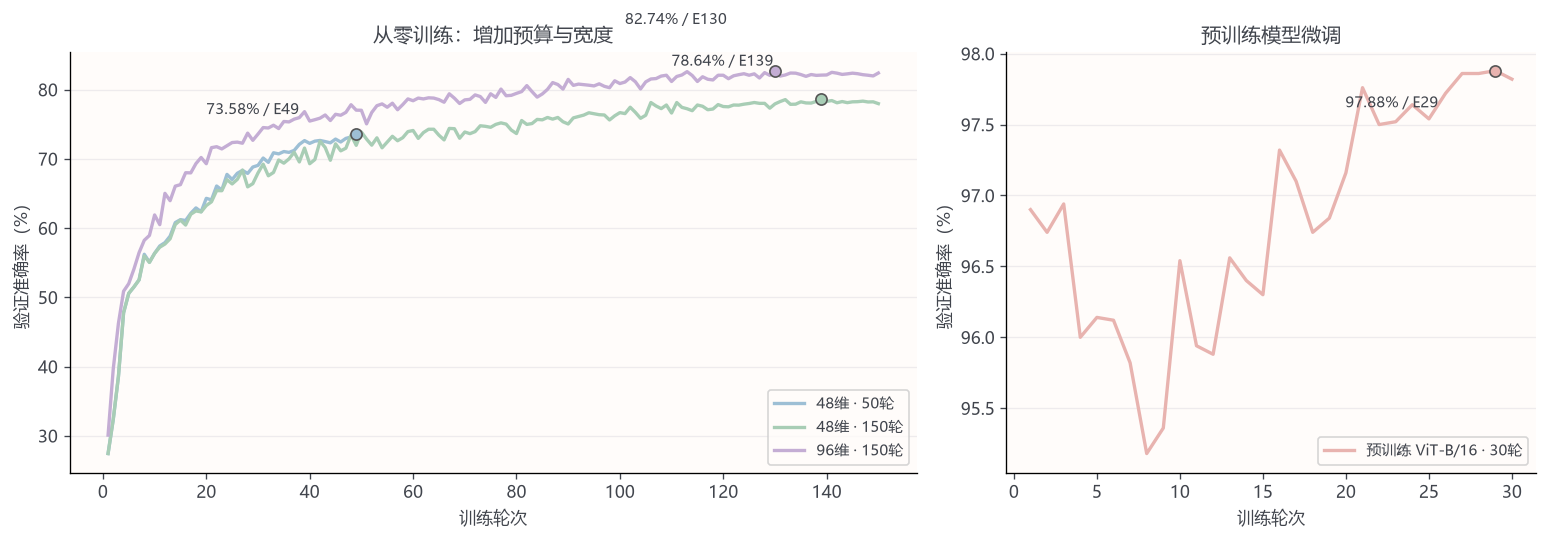

In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4.6),gridspec_kw={'width_ratios':[1.6,1]})
for i,r in enumerate(runs):
    ax=axes[0] if i<3 else axes[1]
    ax.plot([v['epoch'] for v in r['rows']],[v['val_acc'] for v in r['rows']],color=COLORS[i],lw=2,label=r['label'])
    b=r['best'];ax.scatter(b['epoch'],b['val_acc'],color=COLORS[i],edgecolors='#555555',s=45,zorder=3)
    ax.annotate(f"{b['val_acc']:.2f}% / E{b['epoch']}",(b['epoch'],b['val_acc']),xytext=(-90,12+i*8 if i<3 else -22),textcoords='offset points',fontsize=9)
for ax in axes:
    ax.set_xlabel('训练轮次');ax.set_ylabel('验证准确率（%）');ax.grid(axis='y');ax.legend(loc='lower right',fontsize=9)
axes[0].set_title('从零训练：增加预算与宽度');axes[1].set_title('预训练模型微调')
fig.tight_layout();save_show(fig,'01_validation_curves')


## 图2：最终准确率对比

测试结果缺失处明确标记“未评估”，不以验证准确率代替。柱状图纵轴从0开始；所有结果来自单次运行，没有误差棒。

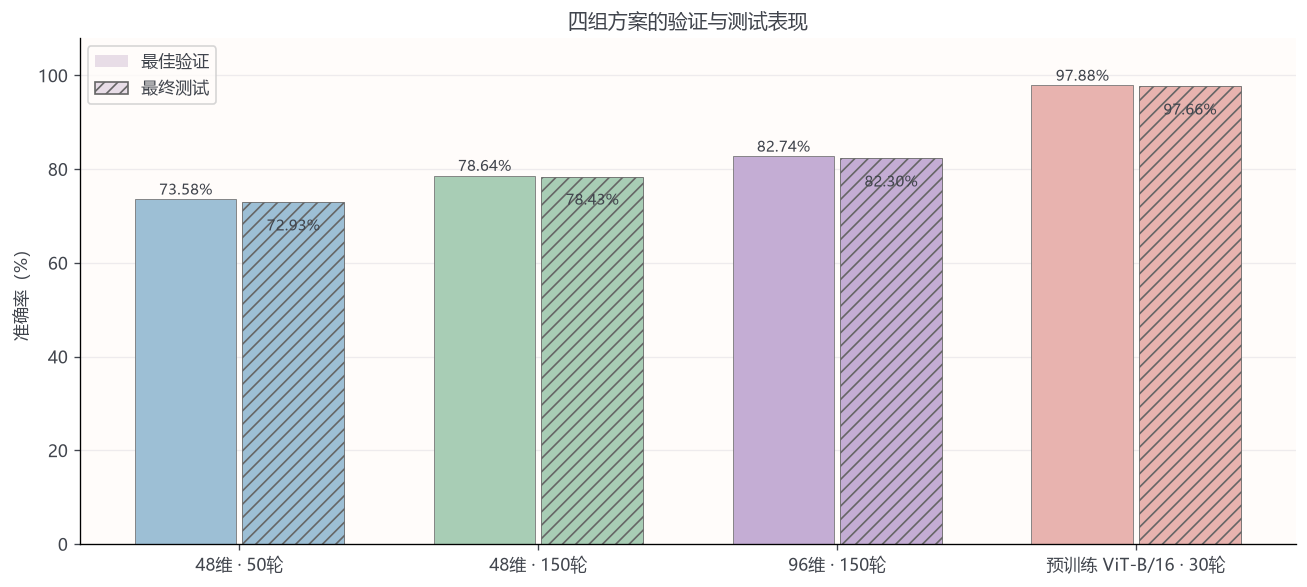

In [4]:
fig,ax=plt.subplots(figsize=(11,5))
for i,r in enumerate(runs):
    v=r['best']['val_acc']
    ax.bar(i-.18,v,.34,color=COLORS[i],edgecolor='#777777',linewidth=.5)
    ax.text(i-.18,v+1,f'{v:.2f}%',ha='center',fontsize=9)
    if r['test'] is not None:
        ax.bar(i+.18,r['test'],.34,color=COLORS[i],hatch='///',edgecolor='#666666',linewidth=.5)
        ax.text(i+.18,r['test']-6,f"{r['test']:.2f}%",ha='center',fontsize=9)
    else: ax.text(i+.18,8,'未评估',ha='center',rotation=90,fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#E8DDE7',label='最佳验证'),Patch(facecolor='#E8DDE7',hatch='///',edgecolor='#666666',label='最终测试')],loc='upper left')
ax.set_xticks(range(4),[r['label'] for r in runs]);ax.set_ylim(0,108);ax.set_ylabel('准确率（%）');ax.set_title('四组方案的验证与测试表现');ax.grid(axis='y');ax.set_axisbelow(True)
fig.tight_layout();save_show(fig,'02_accuracy_comparison')


## 图3：训练与验证的差距

训练准确率在随机增强、dropout开启和参数持续更新时累计；验证准确率是固定模型在验证集上的测量，两者并非严格同口径。训练loss含标签平滑，验证loss为普通交叉熵，不能直接比较其绝对高低。

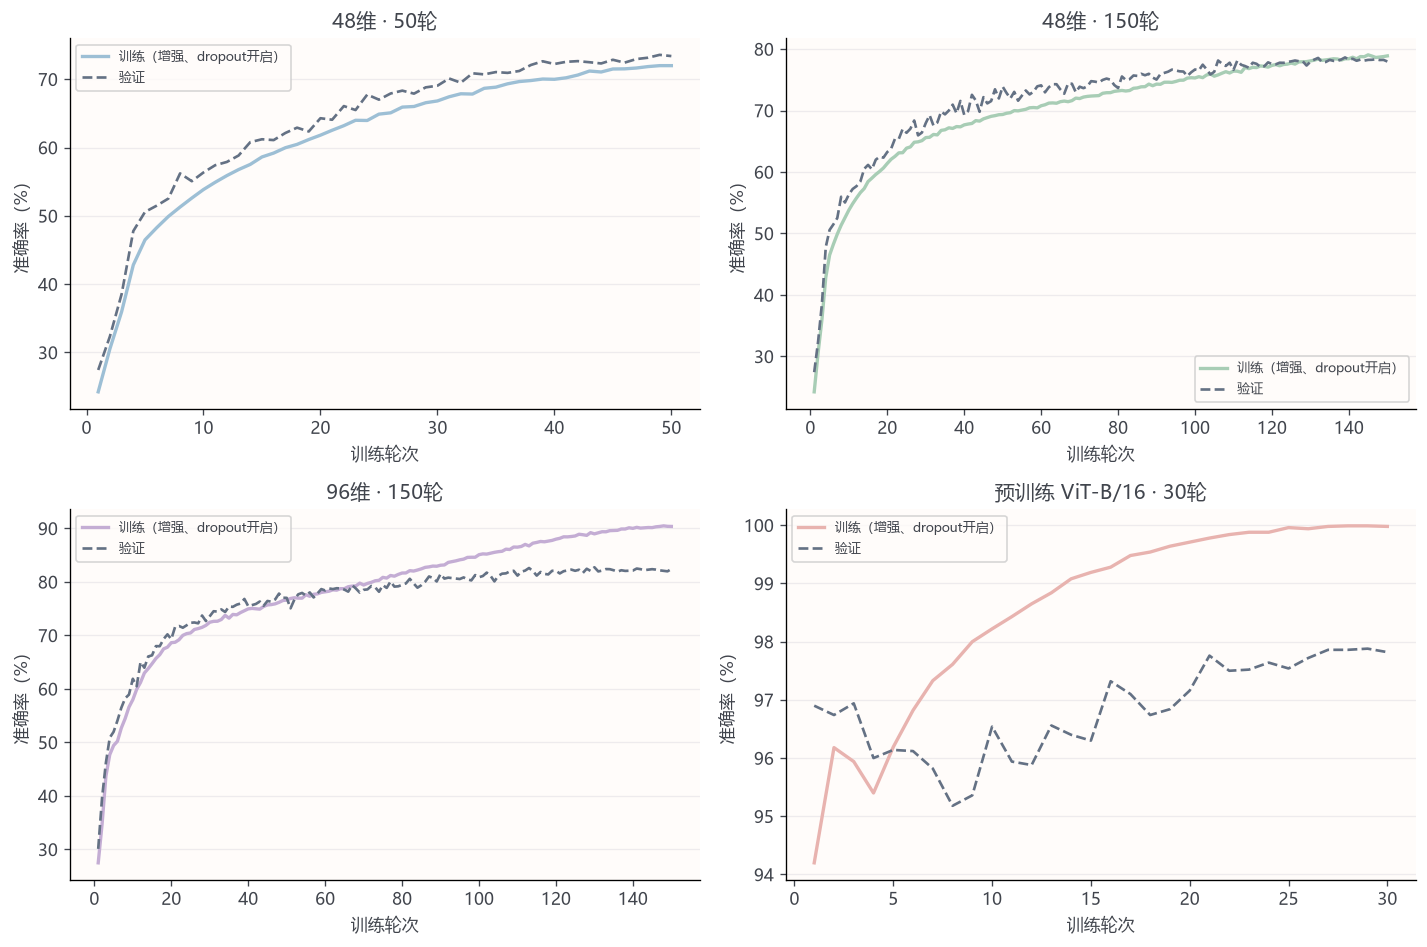

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for i,(ax,r) in enumerate(zip(axes.flat,runs)):
    epochs=[v['epoch'] for v in r['rows']]
    ax.plot(epochs,[v['train_acc'] for v in r['rows']],color=COLORS[i],lw=2,label='训练（增强、dropout开启）')
    ax.plot(epochs,[v['val_acc'] for v in r['rows']],color='#647184',ls='--',lw=1.6,label='验证')
    ax.set_title(r['label']);ax.set_xlabel('训练轮次');ax.set_ylabel('准确率（%）');ax.grid(axis='y');ax.legend(fontsize=8)
fig.tight_layout();save_show(fig,'03_train_validation_gap')


## 图4：效果与计算成本

参数量横轴使用对数刻度；另一子图使用实测日志循环耗时。预训练成本未计入本地微调耗时，不能据此声称它的总体训练成本更低。不同方案的单轮计算量差异很大，不能仅凭轮数比较成本。

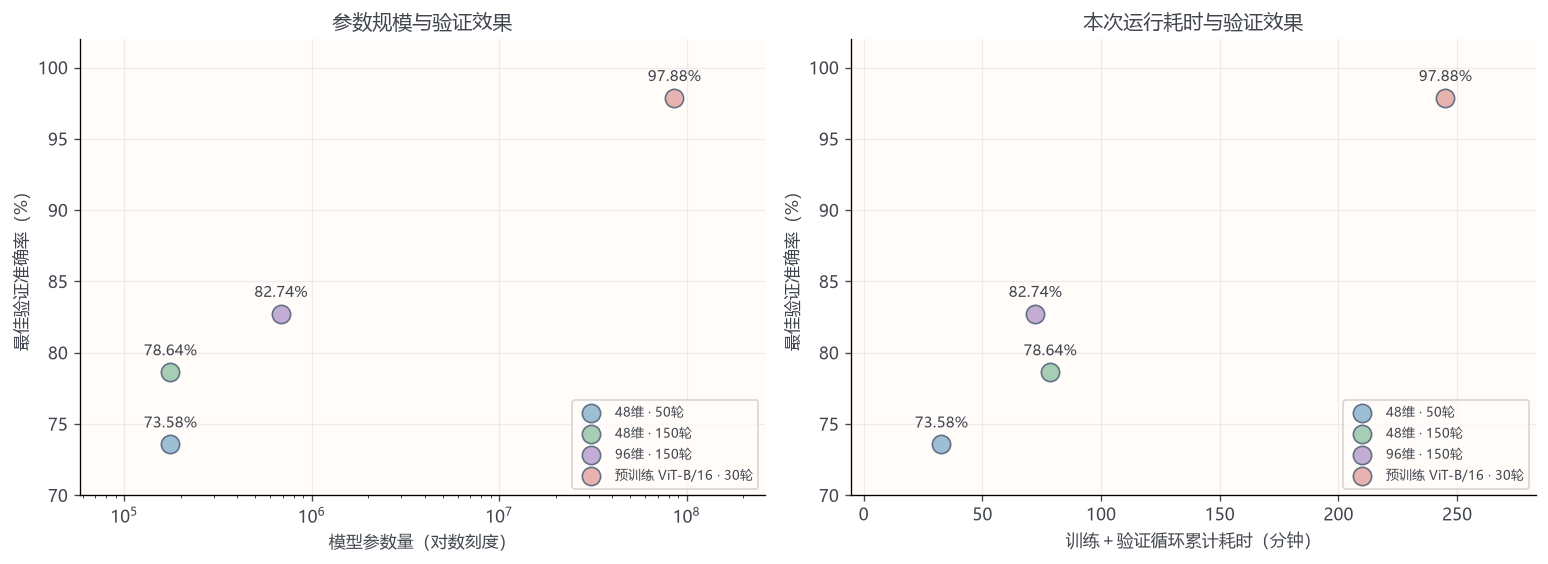

In [6]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for i,r in enumerate(runs):
    for ax,x in [(axes[0],r['params']),(axes[1],r['minutes'])]:
        ax.scatter(x,r['best']['val_acc'],s=120,color=COLORS[i],edgecolors='#647184',label=r['label'],zorder=3)
        ax.annotate(f"{r['best']['val_acc']:.2f}%",(x,r['best']['val_acc']),xytext=(0,10),textcoords='offset points',ha='center',fontsize=9)
axes[0].set_xscale('log');axes[0].set_xlabel('模型参数量（对数刻度）');axes[0].set_title('参数规模与验证效果')
axes[1].set_xlabel('训练＋验证循环累计耗时（分钟）');axes[1].set_title('本次运行耗时与验证效果')
for ax in axes:
    ax.set_ylabel('最佳验证准确率（%）');ax.set_ylim(70,102);ax.margins(x=.18);ax.grid();ax.legend(loc='lower right',fontsize=8)
fig.tight_layout();save_show(fig,'04_accuracy_cost')


## 结论与边界

1. **延长预算有效**：48维模型由50轮改为150轮，最佳验证准确率从73.58%升至78.64%，提升5.06个百分点。对应余弦退火周期也延长，因此不能解释为固定学习率轨迹下简单多跑100轮。
2. **增加容量继续有效**：相同150轮预算，宽度48→96，最佳验证准确率升至82.74%，提升4.10个百分点；参数量由175,738增加到683,242。宽模型后期训练约90%、验证约82%，泛化差距扩大。
3. **预训练整体方案最好**：最佳验证97.88%，最佳轮次29；独立官方测试集97.66%、loss 0.1877。相对宽模型验证提高15.14个百分点，但同时改变了外部数据、模型大小、输入分辨率和优化设置，不能把提升归因于单个因素。
4. 四组实验均使用固定随机种子 42，用于模型初始化、训练/验证集划分和训练数据加载器的随机生成器。复现时应同时保持代码、数据、超参数及软件环境一致。固定种子有助于复现本次结果，但不能保证不同硬件和软件环境下得到完全相同的数值。每组仅运行一次，尚未评估不同随机种子带来的波动，因此不作统计显著性结论。
5. 发布前已对两组最佳权重进行最终测试：48维150轮78.43%、96维150轮82.30%；结果仅作最终评估，未据此重新选择超参数。
6. 最佳模型错误分析已单独完成：234张错误中，猫→狗30张、狗→猫30张；类别召回率最低为猫94.7%。这些测试错误用于描述结果，不作为反复调参依据。

## 文件索引

- `data/`：四组原始日志快照和可用配置文件。
- `figures/`：四组马卡龙风格图表，PNG与SVG格式。
- `实验汇总.csv`：实验配置、结果与成本表。
- 原始错误分析：`error_analysis/错误分析.md`（仓库副本；本地原图保留在实验目录）。

重新运行依赖：Python、matplotlib、Jupyter/IPython；不需要PyTorch或下载模型。日志和配置取自本次实验文件，模型参数量依据此前模型工厂实测记录。